In [2]:
### Python DA Capstone Project - Marketing Campaign Performance Insights

## Module End Assignment: Python For Data Analysis “Social Media Engagement Analytics”


## Task 1 — Data Import & Setup

## Import CSV using Pandas

import pandas as pd
import numpy as np


In [3]:
## Load the CSV dataset

df = pd.read_csv("social_media_engagement_5000.csv")

In [4]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [5]:
## Check/convert data types

print(df.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [6]:
print(df.info())   ## to Check the dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [7]:
print(df.dtypes)   ## to Check the data types

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [8]:
## Convert date columns to datetime

df['posted_at'] = pd.to_datetime(        ## it converts the column into a date and time data type
    df['posted_at'],
    format='%d-%m-%Y',                   ## it is used to specifies the date format
    errors='coerce'                      ## it converts invalid dates to NaT
)


In [9]:
print(df['posted_at'].head())

print(df.dtypes)

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]
user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [10]:
## Task 2 — Data Cleaning

# Cleaning Missing Data
#1. Detect missing values

import pandas as pd

df = pd.read_csv("social_media_engagement_5000.csv")

print(df.isnull().sum())   ## it Detect missing values using isnull()


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [11]:
print(df.isna().sum())      ## it Detect missing values using isna()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [12]:
print("Total missing values:", df.isna().sum().sum())   ## this count the total missing values across the entire dataset

Total missing values: 900


In [13]:
## 2. Handle missing values in the Age column using Median

# to Check missing values in age
print("Missing age values:", df['age'].isnull().sum())

# To Calculate median age
median_age = df['age'].median()
print("Median age:", median_age)

# it Fills missing age values using median
median_age = round(df['age'].median())
df['age'] = df['age'].fillna(median_age)

print("Missing age values after filling:", df['age'].isnull().sum())

Missing age values: 150
Median age: 38.0
Missing age values after filling: 0


In [14]:
##  Handle missing values in the Gender column using Mode

# To Check missing values in gender
print("Missing gender values:", df['gender'].isnull().sum())

# To Find the most frequent gender
gender_mode = df['gender'].mode()[0]
print("Most frequent gender:", gender_mode)

# it Fills missing values using mode
df['gender'] = df['gender'].fillna(gender_mode)


print("Missing gender values after filling:", df['gender'].isnull().sum())


Missing gender values: 150
Most frequent gender: Male
Missing gender values after filling: 0


In [15]:
## Handle missing values using dropna()

df_dropped = df.dropna()          ## The dropna() method removes rows containing missing values

print("Original dataset shape:", df.shape)   ## it displays the original number of rows and columns
print("After dropping missing values:", df_dropped.shape)   ## it stores the cleaned copy



Original dataset shape: (5000, 19)
After dropping missing values: (4425, 19)


In [16]:
## Handle missing numerical values using the median

numerical_columns = [
    'age',
    'likes',
    'comments',
    'shares'
]

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())  ## The median is often useful because it is less affected by extreme values than the mean

print(df[numerical_columns].isnull().sum())

age         0
likes       0
comments    0
shares      0
dtype: int64


In [17]:
## Handle missing categorical values using mode

categorical_columns = [
    'gender',
    'sentiment'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df[categorical_columns].isnull().sum())


gender       0
sentiment    0
dtype: int64


In [18]:
## Handle missing values using forward fill

df_ffill = df.copy()     ## Forward fill replaces a missing value with the previous row's value

df_ffill = df_ffill.ffill()

print(df_ffill.isnull().sum())


user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [19]:
## Handle missing values using backward fill

df_bfill = df.copy()    ## Backward fill replaces a missing value with the next row's value

df_bfill = df_bfill.bfill()

print(df_bfill.isnull().sum())


user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [20]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values after cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

Total missing values:
0


In [21]:
## 3. Duplicate Handling — Identify and Remove Duplicates


print("Duplicate post IDs:", df['post_id'].duplicated().sum())

print(df[df['post_id'].duplicated(keep=False)].sort_values('post_id'))


Duplicate post IDs: 9
      user_id   age  gender    country  post_id post_type post_category  \
3941    73811  25.0    Male     Canada   301157     video       fashion   
3336    82127  29.0    Male      India   301157     video       fashion   
2153    59104  28.0  Female     Canada   444417     image       fashion   
4993    82779  44.0    Male         UK   444417      text          food   
2117    69189  44.0  Female      India   448492      text         music   
693     15713  38.0   Other        USA   448492     image       fitness   
4888    22453  45.0  Female  Australia   457659     image       fitness   
4773    29288  14.0   Other        USA   457659      text          tech   
3791    92152  57.0    Male         UK   671719     image     lifestyle   
204     73734  38.0  Female         UK   671719     image          tech   
1732    38541  38.0    Male        UAE   778627      reel     lifestyle   
560     61934  38.0  Female        USA   778627      text         music   
347

In [22]:
# Check the number of duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())   ## it identifies rows that is duplicate

Number of duplicate rows: 0


In [23]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5000, 19)


In [24]:
## 4. Data Formatting — Fix Incorrect Data Types

print(df.dtypes)


user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [25]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

print(df['posted_at'].dtype)

datetime64[ns]


In [26]:
# Convert engagement counts into integers

count_columns = ['likes', 'comments', 'shares']

for col in count_columns:
    df[col] = df[col].fillna(df[col].median()).round().astype('int64')

print(df[count_columns].dtypes)  ## This fills missing values with the median, rounds the values to whole numbers, and converts the columns to integers


likes       int64
comments    int64
shares      int64
dtype: object


In [27]:
# Standardize Categories — Gender
#  to Check the existing categories

print(df['gender'].value_counts(dropna=False))


gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [28]:
## Standardize the labels

df['gender'] = (
    df['gender']
    .str.strip()    ## it removes unnecessary spaces
    .str.lower()   ## it converts text to lowercase
    .map({                 ## this function converts the recognized labels into a consistent format
        'male': 'Male',
        'female': 'Female',
        'other': 'Other'
    })
)

In [29]:
category_columns = [
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for col in category_columns:
    df[col] = df[col].str.strip().str.lower()

print(df[category_columns].head())


  country post_type post_category device_type sentiment
0  brazil     image       fitness      mobile  negative
1  brazil      reel          food      mobile  negative
2      uk      text          food      tablet  positive
3  france      text       fitness      mobile  negative
4      uk     image       fitness      mobile  negative


In [30]:
## Correct Unrealistic Values in Likes, Comments, and Shares

# to Check suspicious engagement counts

count_columns = ['likes', 'comments', 'shares']

for col in count_columns:
    print(f"\n{col} summary:")
    print(df[col].describe())

    print(
        "Negative values:",
        (df[col] < 0).sum()
    )

    print(
        "Greater than impressions:",
        (df[col] > df['impression_count']).sum()
    )




likes summary:
count     5000.000000
mean     10107.012400
std       5702.293014
min         10.000000
25%       5235.000000
50%      10106.000000
75%      14959.000000
max      19998.000000
Name: likes, dtype: float64
Negative values: 0
Greater than impressions: 464

comments summary:
count    5000.000000
mean     1502.039800
std       856.393312
min         0.000000
25%       792.000000
50%      1497.000000
75%      2235.250000
max      2999.000000
Name: comments, dtype: float64
Negative values: 0
Greater than impressions: 65

shares summary:
count    5000.0000
mean     1002.9106
std       570.8552
min         0.0000
25%       511.0000
50%      1012.0000
75%      1483.0000
max      1999.0000
Name: shares, dtype: float64
Negative values: 0
Greater than impressions: 55


In [31]:
 # to Check missing values
print("\nRemaining missing values:")
print(df.isnull().sum())

#  to Display cleaned data
print("\nCleaned dataset:")
print(df.head())


Remaining missing values:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

Cleaned dataset:
   user_id   age  gender country  post_id post_type post_category  likes  \
0    25795  43.0  Female  brazil   496713     image       fitness   7011   
1    10860  33.0    Male  brazil   157326      reel          food  11750   
2    86820  32.0  Female      uk   109864      text          food   4862   
3    64886  51.0   Other  france   848877      text       fitness   5350   
4    16265  34.0   Other      uk   449706     image       fitness  12682   

   comments  shares  watch_time_sec  impression_count  posted_at  \

In [32]:
## 5.Feature Cleaning
#  Extract hashtag count
df['hashtag_count'] = df['hashtags'].fillna('').str.count('#')

print(df[['hashtags', 'hashtag_count']].head(10))

# df['hashtags'] it selects the hashtags column
## fillna('') it replaces missing hashtag values with an empty string
# str.count('#') it counts how many # symbols appear in each row
# hashtag_count it stores the result in a new column

# to Check sentiment labels before cleaning
print(df['sentiment'].value_counts(dropna=False))  ## counts the occurrences of each sentiment

# Standardize sentiment labels
df['sentiment'] = (
    df['sentiment']
    .str.strip()
    .str.lower()
)

#Handle missing sentiment values
df['sentiment'] = df['sentiment'].fillna('unknown')

# Check sentiment labels after cleaning
print(df['sentiment'].value_counts())


# Display the updated dataset
print("\nUpdated Dataset:")
print(df[['hashtags', 'hashtag_count', 'sentiment']].head(10))

 # Check the new column's data type
print("\nHashtag Count Data Type:")
print(df['hashtag_count'].dtype)


                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

Updated Dataset:
                  hashtags  hashtag_count sentiment
0    #foodie #travel #love              3  negative
1                 #fitness              1  negative
2                  #foodie              1  positive
3      #music #foodie #fun              3  negative
4                  #travel              1  negative
5                 #fitness        

In [33]:
## Task 3 — Data Exploration using Pandas

## 1. View the dataset structure

# First five rows
display(df.head())

# Last five rows
display(df.tail())

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,france,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Dataset shape: (5000, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [34]:
## 2. Check column types and information

# Overview: column names, non-missing counts, and data types
df.info()

# Data type of each column
print(df.dtypes)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [35]:
## 3. Generate summary statistics

# Statistics for numeric columns
display(df.describe())

# Include text and category columns too
display(df.describe(include="all"))


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.012400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10106.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000,5000,5000,5000,5000.000000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,3,761,NaN,NaN
top,NaN,NaN,Male,india,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,mobile,positive,#tech,NaN,NaN
freq,NaN,NaN,1849,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4517,1684,2513,201,NaN,NaN
mean,54561.890800,38.440400,NaN,NaN,548042.909000,NaN,NaN,10107.012400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,NaN,NaN,NaN,NaN,0.964356,1.998600
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,NaN,NaN,NaN,NaN,0.006363,1.000000
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,NaN,NaN,NaN,NaN,0.145781,1.000000
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,10106.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,NaN,NaN,NaN,NaN,0.253896,2.000000
75%,77180.500000,51.000000,NaN,NaN,771574.500000,NaN,NaN,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,NaN,NaN,NaN,NaN,0.504794,3.000000
max,99963.000000,64.000000,NaN,NaN,999455.000000,NaN,NaN,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,NaN,NaN,NaN,NaN,191.504348,3.000000


In [36]:
## 4. Explore categorical columns

for column in ["post_type", "country", "gender", "sentiment"]:
    if column in df.columns:
        print(f"\n{column}:")
        print("Counts, including missing values:")
        print(df[column].value_counts(dropna=False))
        print("Unique values:", df[column].unique())
        print("Number of distinct values:", df[column].nunique(dropna=False))



post_type:
Counts, including missing values:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
Unique values: ['image' 'reel' 'text' 'video']
Number of distinct values: 4

country:
Counts, including missing values:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64
Unique values: ['brazil' 'uk' 'france' 'canada' 'japan' 'australia' 'india' 'uae'
 'germany' 'usa']
Number of distinct values: 10

gender:
Counts, including missing values:
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
Unique values: ['Female' 'Male' 'Other']
Number of distinct values: 3

sentiment:
Counts, including missing values:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
Unique values: ['negative' 'positive' 'neutral']
Number of distinct values: 3


In [37]:
## 5. Create a correlation matrix

#  Select numeric columns, then calculate their correlations
numeric_df = df.select_dtypes(include="number")
print("Numeric columns included:")
print(numeric_df.columns.tolist())

print("\nCorrelation matrix:")
display(numeric_df.corr().round(2))


Numeric columns included:
['user_id', 'age', 'post_id', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count', 'engagement_rate', 'hashtag_count']

Correlation matrix:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.00,-0.01,0.02,0.03,-0.03,0.01,-0.02,0.02,0.01,-0.00,-0.01
age,-0.01,1.00,-0.01,-0.04,-0.01,0.01,0.01,0.01,-0.02,0.01,0.01
post_id,0.02,-0.01,1.00,0.01,-0.01,0.00,0.02,-0.01,-0.00,0.01,0.01
likes,0.03,-0.04,0.01,1.00,-0.02,0.00,0.01,0.01,-0.02,0.09,-0.00
comments,-0.03,-0.01,-0.01,-0.02,1.00,0.01,-0.02,-0.01,-0.01,0.00,-0.02
shares,0.01,0.01,0.00,0.00,0.01,1.00,0.01,-0.01,-0.01,0.02,0.01
watch_time_sec,-0.02,0.01,0.02,0.01,-0.02,0.01,1.00,-0.00,0.00,-0.00,-0.02
impression_count,0.02,0.01,-0.01,0.01,-0.01,-0.01,-0.00,1.00,-0.02,-0.23,-0.00
follower_count,0.01,-0.02,-0.00,-0.02,-0.01,-0.01,0.00,-0.02,1.00,0.00,0.01
engagement_rate,-0.00,0.01,0.01,0.09,0.00,0.02,-0.00,-0.23,0.00,1.00,0.01


In [38]:
## 6. Summarize metrics with groupby()

# Average likes by post type
if {"post_type", "likes", "comments", "shares"}.issubset(df.columns):
    print("Engagement summary by post type:")
    display(
        df.groupby("post_type")[["likes", "comments", "shares"]]
          .mean()
          .round(2)
    )

# Average impressions by country
if {"country", "impression_count"}.issubset(df.columns):
    print("\nAverage impressions by country:")
    display(
        df.groupby("country")["impression_count"]
          .mean()
          .round(2)
          .sort_values(ascending=False)
    )

Engagement summary by post type:


,likes,comments,shares
post_type,,,
image,10104.88,1525.24,1019.29
reel,10037.82,1504.19,982.04
text,10100.16,1499.11,1013.99
video,10188.61,1479.16,996.83



Average impressions by country:


,impression_count
country,
india,52462.39
france,51727.67
usa,51263.87
uk,51119.39
japan,49616.14
brazil,49193.17
uae,48928.41
canada,48703.15
germany,48605.41


In [39]:
## Task 4 — Data Wrangling

## Concatenate rows from files with the same columns

# Example: append two datasets that have the same columns
# df_part1 = pd.read_csv("part1.csv")
# df_part2 = pd.read_csv("part2.csv")

# combined_df = pd.concat([df_part1, df_part2], ignore_index=True)

## Merge two DataFrames using a shared key

# Example: add user details to posts using user_id
# merged_df = pd.merge(posts_df, users_df, on="user_id", how="left")


In [40]:
## Create new fields

## Hashtag count

if "hashtags" in df.columns:
    df["hashtag_count"] = (
        df["hashtags"]
        .fillna("")
        .astype(str)
        .str.count("#")
    )

print(df[["hashtags", "hashtag_count"]].head())


                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


In [41]:
# Engagement score

engagement_columns = ["likes", "comments", "shares"]

if all(col in df.columns for col in engagement_columns):
    df["engagement_score"] = (
        df[engagement_columns]
        .fillna(0)
        .sum(axis=1)
    )

    print(df[engagement_columns + ["engagement_score"]].head())
else:
    print("Could not create engagement_score")

   likes  comments  shares  engagement_score
0   7011       354    1157              8522
1  11750      2606    1807             16163
2   4862       344     955              6161
3   5350      1083    1049              7482
4  12682      2735    1300             16717


In [42]:
# log-transformed metrics

for col in ["likes", "comments", "shares", "impression_count"]:
    if col in df.columns:
        df[f"log_{col}"] = np.log1p(df[col].clip(lower=0))

print(df.head())


   user_id   age  gender country  post_id post_type post_category  likes  \
0    25795  43.0  Female  brazil   496713     image       fitness   7011   
1    10860  33.0    Male  brazil   157326      reel          food  11750   
2    86820  32.0  Female      uk   109864      text          food   4862   
3    64886  51.0   Other  france   848877      text       fitness   5350   
4    16265  34.0   Other      uk   449706     image       fitness  12682   

   comments  shares  ...  device_type  sentiment               hashtags  \
0       354    1157  ...       mobile   negative  #foodie #travel #love   
1      2606    1807  ...       mobile   negative               #fitness   
2       344     955  ...       tablet   positive                #foodie   
3      1083    1049  ...       mobile   negative    #music #foodie #fun   
4      2735    1300  ...       mobile   negative                #travel   

   engagement_rate  hashtag_count engagement_score log_likes log_comments  \
0         0.190

In [43]:
## Group summaries

metrics = [
    "likes",
    "comments",
    "shares",
    "impression_count",
    "engagement_score"
]

metrics = [column for column in metrics if column in df.columns]

def summarize_by_category(df, category):

    # Check that the category column exists
    if category not in df.columns:
        print(f"Column '{category}' was not found in the dataset.")
        return

    if not metrics:
        print("No engagement metric columns were found.")
        return

    # Group rows by category and calculate the average metrics
    averages = (
        df.groupby(category, dropna=False)[metrics]
          .mean()
          .round(2)
    )

    # Count the number of posts in each category
    post_counts = (
        df.groupby(category, dropna=False)
          .size()
          .rename("post_count")
    )

    # Combine the counts and averages into one table
    summary = post_counts.to_frame().join(averages)

    print(f"\nSummary by {category}:")
    display(summary.sort_values("post_count", ascending=False))

# Create the three requested summaries

summarize_by_category(df, "post_type")
summarize_by_category(df, "country")
summarize_by_category(df, "sentiment")



Summary by post_type:


,post_count,likes,comments,shares,impression_count,engagement_score
post_type,,,,,,
reel,1283,10037.82,1504.19,982.04,50462.60,12524.05
image,1247,10104.88,1525.24,1019.29,49727.42,12649.40
text,1245,10100.16,1499.11,1013.99,49987.22,12613.26
video,1225,10188.61,1479.16,996.83,49862.01,12664.61



Summary by country:


,post_count,likes,comments,shares,impression_count,engagement_score
country,,,,,,
india,535,9962.49,1494.92,1035.32,52462.39,12492.73
canada,513,10063.08,1546.58,996.25,48703.15,12605.91
brazil,504,9886.70,1490.43,1008.86,49193.17,12385.99
uae,503,10227.50,1541.21,989.08,48928.41,12757.79
usa,501,10122.37,1457.96,995.14,51263.87,12575.47
france,496,10372.89,1478.70,1051.81,51727.67,12903.40
australia,493,10294.14,1485.80,1029.69,48346.38,12809.64
uk,493,9935.66,1463.04,985.68,51119.39,12384.39
germany,490,10130.48,1531.83,973.38,48605.41,12635.69



Summary by sentiment:


,post_count,likes,comments,shares,impression_count,engagement_score
sentiment,,,,,,
positive,2513,10180.08,1480.65,1005.09,50248.11,12665.81
neutral,1527,9923.21,1528.40,996.57,49515.97,12448.18
negative,960,10208.11,1516.09,1007.31,50191.96,12731.51


In [44]:
## Task 5 — Statistical Analysis

# Match assignment terms to the column names used in dataset

column_options = {
    "likes": ["likes"],
    "comments": ["comments"],
    "shares": ["shares"],
    "watch_time": ["watch_time", "watch_time_sec"],
    "engagement_rate": ["engagement_rate"],
    "followers": ["followers", "follower_count"]
}

# Pick the first matching column for each metric

selected_columns = {}
for metric, options in column_options.items():
    match = next((col for col in options if col in df.columns), None)
    if match:
        selected_columns[metric] = match
    else:
        print(f"Column for '{metric}' was not found. Checked: {options}")

# Calculate statistics for each matched column

for metric, column in selected_columns.items():
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    if values.empty:
        print(f"\n{metric} ({column}): no numeric values to analyze.")
        continue

    print(f"\n--- {metric} (column: {column}) ---")
    print(f"Count: {values.count()}")
    print(f"Mean: {values.mean():.2f}")
    print(f"Median: {values.median():.2f}")

    modes = values.mode()
    print("Mode:", ", ".join(f"{value:g}" for value in modes))

    print(f"Standard deviation: {values.std():.2f}")
    print(f"Variance: {values.var():.2f}")

    print("Percentiles:")
    print(values.quantile([0.25, 0.50, 0.75, 0.90]).rename({
        0.25: "25th percentile",
        0.50: "50th percentile",
        0.75: "75th percentile",
        0.90: "90th percentile"
    }).round(2))

    print(f"Skewness: {values.skew():.2f}")
    print(f"Kurtosis: {values.kurt():.2f}")



--- likes (column: likes) ---
Count: 5000
Mean: 10107.01
Median: 10106.00
Mode: 10106
Standard deviation: 5702.29
Variance: 32516145.62
Percentiles:
25th percentile     5235.0
50th percentile    10106.0
75th percentile    14959.0
90th percentile    18016.3
Name: likes, dtype: float64
Skewness: -0.01
Kurtosis: -1.15

--- comments (column: comments) ---
Count: 5000
Mean: 1502.04
Median: 1497.00
Mode: 1497
Standard deviation: 856.39
Variance: 733409.50
Percentiles:
25th percentile     792.00
50th percentile    1497.00
75th percentile    2235.25
90th percentile    2695.10
Name: comments, dtype: float64
Skewness: 0.00
Kurtosis: -1.14

--- shares (column: shares) ---
Count: 5000
Mean: 1002.91
Median: 1012.00
Mode: 1012
Standard deviation: 570.86
Variance: 325875.66
Percentiles:
25th percentile     511.0
50th percentile    1012.0
75th percentile    1483.0
90th percentile    1795.1
Name: shares, dtype: float64
Skewness: -0.01
Kurtosis: -1.15

--- watch_time (column: watch_time_sec) ---
Count:

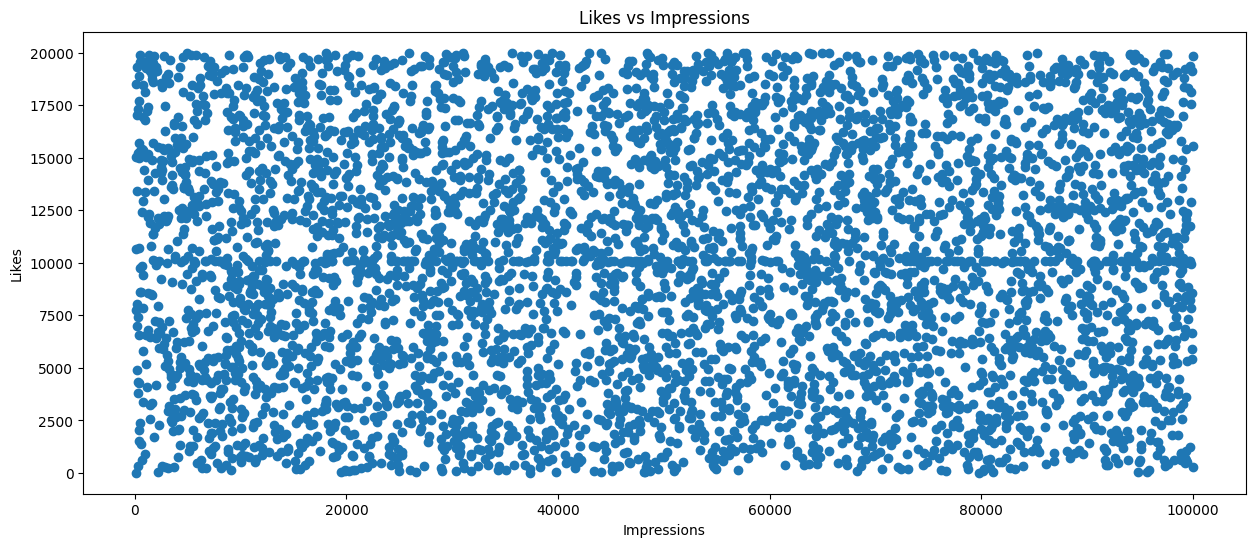

In [78]:
## Task 6 — Data Visualization using Matplotlib

import pandas as pd
import matplotlib.pyplot as plt

# Plot 1: Scatter Plot — Likes vs Impressions

plt.figure(figsize=(15, 6))

plt.scatter(df.impression_count,df.likes)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()


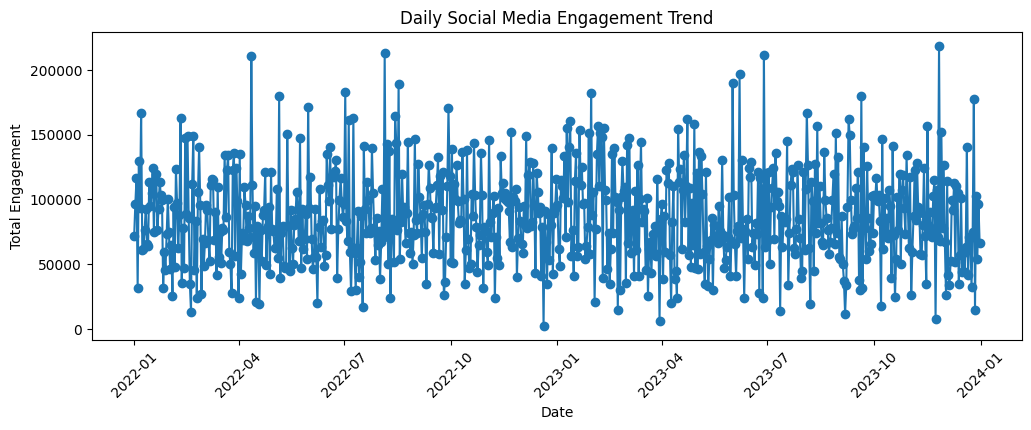

In [81]:
## Plot 2: Line Chart — Daily Engagement Trend

# Calculate total engagement for each post
df['total_engagement'] = (
    df['likes'].fillna(0)
    + df['comments'].fillna(0)
    + df['shares'].fillna(0)
)

# Group engagement by date
daily_engagement = (
    df.groupby(df['posted_at'].dt.date)['total_engagement']
    .sum()
    .sort_index()
)

# Create line chart
plt.figure(figsize=(12,4))

plt.plot(
    daily_engagement.index,
    daily_engagement.values,
    marker='o'
)

plt.title('Daily Social Media Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Total Engagement')

plt.xticks(rotation=45)

plt.show()


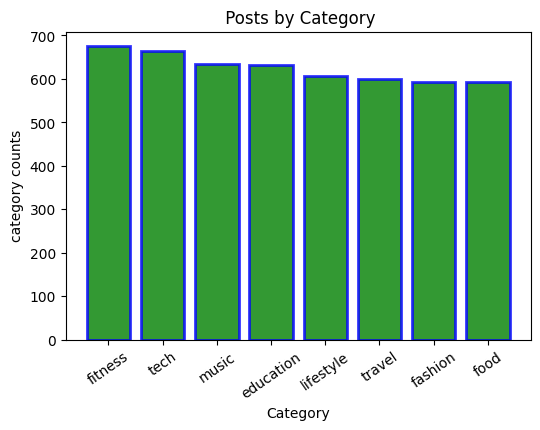

In [87]:
## Plot 3: Bar Chart — Posts by Category

# Count posts in each category
category_counts = df['post_category'].value_counts()   ## it counts the posts in each category

# Create bar chart
plt.figure(figsize=(6,4))

plt.bar(
    category_counts.index,
    category_counts.values,color="green",edgecolor=
        'blue',linewidth=2,alpha=.8,align="center"
)

plt.title(' Posts by Category')
plt.xlabel('Category')
plt.ylabel('category counts')

plt.xticks(rotation=35)

plt.show()


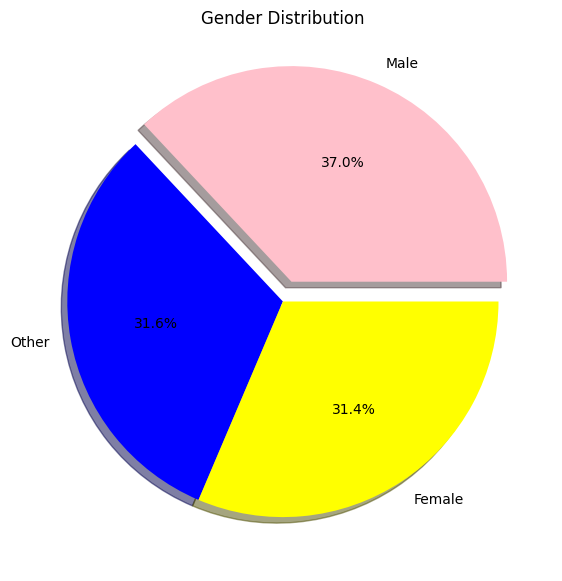

In [89]:
## Plot 4: Pie Chart — Gender Distribution

# Count users by gender
gender= (df['gender'].value_counts())

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(gender.values,labels=gender.index, autopct='%1.1f%%',
explode=[0.1,0,0],
colors=["pink","blue","yellow"],
shadow=True)

plt.title('Gender Distribution')
plt.show()


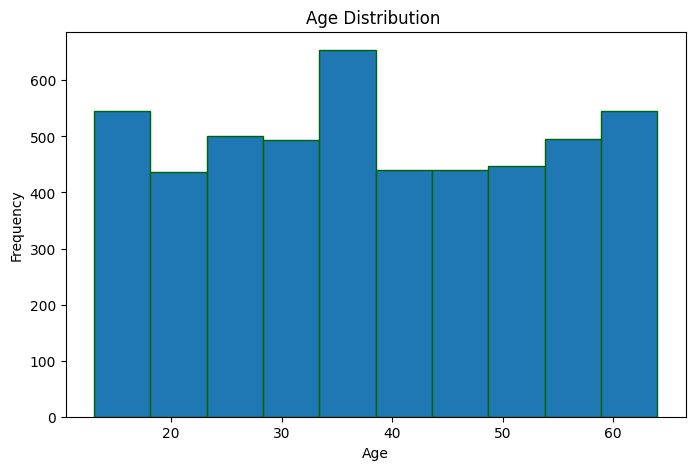

In [90]:
## 5. Histogram — Age Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df['age'].dropna(),
    bins=10,
    edgecolor='darkgreen'
)

plt.title('Age Distribution ')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()


Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares', 'log_impression_count', 'total_engagement'],
      dtype='object')


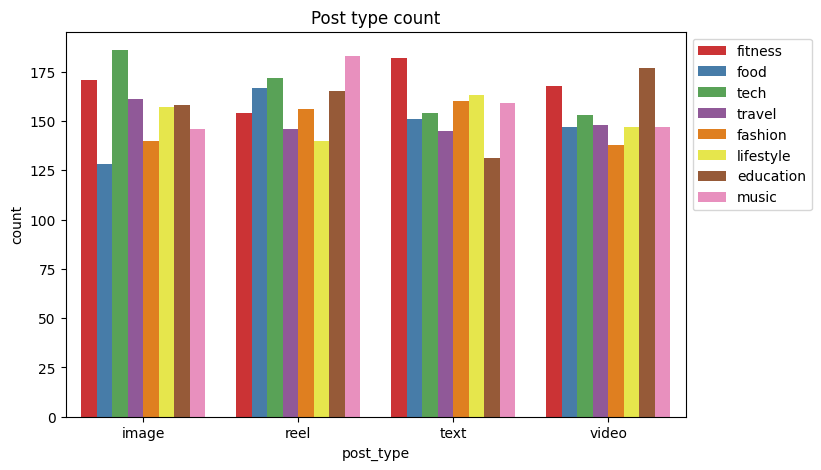

In [96]:
### Data Visualization Using Seaborn

import seaborn as sns

## 6. Count Plot — Post Type

plt.figure(figsize=(8, 5))

print(df.columns)

sns.countplot(data=df, x='post_type',hue="post_category",palette="Set1")

plt.legend(bbox_to_anchor=(1,1))
plt.title("Post type count")
plt.show()



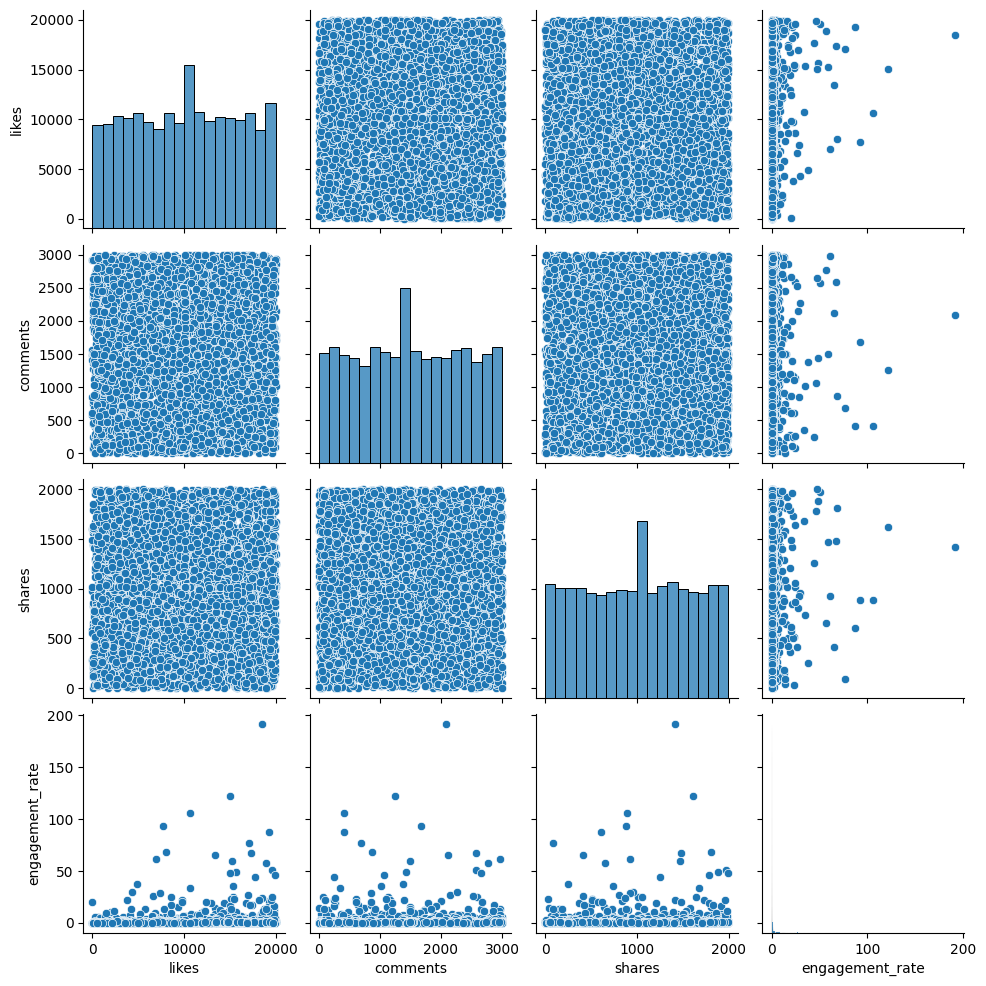

In [99]:
## 7. Pair Plot — Numerical Features
sns.pairplot(df[["likes","comments","shares","engagement_rate"]])
plt.show()


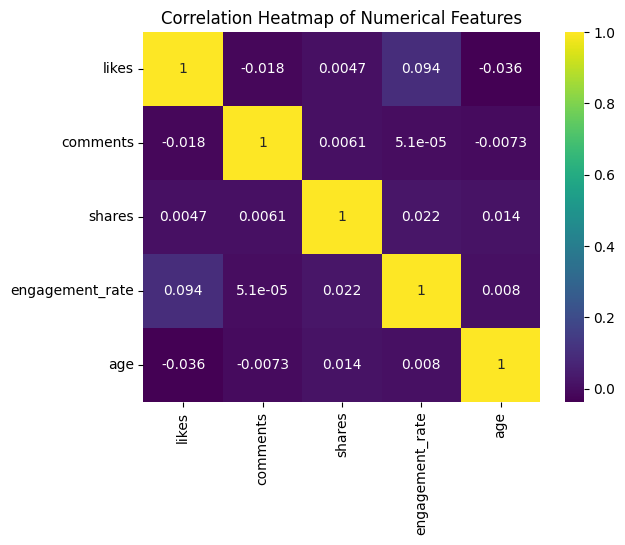

In [100]:
### 8. Heatmap — Correlation Matrix

sns.heatmap(df[["likes","comments","shares","engagement_rate","age"]].corr(),cmap="viridis",annot=True)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


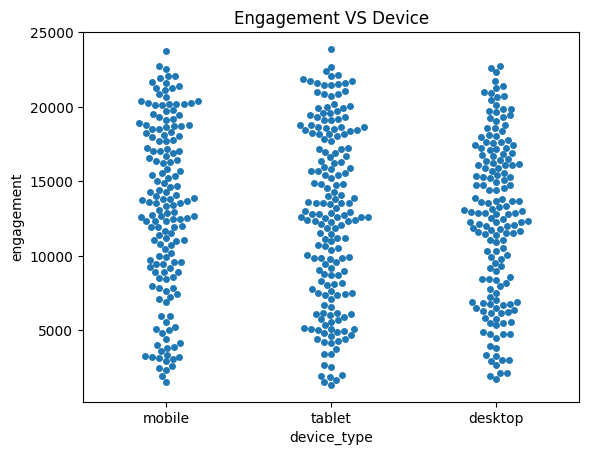

In [101]:
#6. Swarm plot — Engagement vs device
df["engagement"]=df["likes"]+df["comments"]+df["shares"]
sns.swarmplot(x="device_type",y="engagement",
              data=df.sample(500))
plt.title("Engagement VS Device")
plt.show()


In [103]:
#Plotly (Interactive)
 # Interactive line chart/bar chart/bubble/scatter chart
import pandas as pd
import plotly.express as px
#1. Interactive line chart — Daily engagement
print(df.columns)
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst="True")
df["engagement"]=df["likes"]+df["comments"]+df["shares"]
daily=df.groupby("posted_at")["engagement"].sum().reset_index()
fig=px.line(daily,x="posted_at",y="engagement",title="daily engagement trend")
fig.show()

In [103]:
#Interactive bar chart — Average likes by category
avg_likes = df.groupby("post_category")["likes"].mean().reset_index()

fig=px.bar(avg_likes,x="post_category",y="likes",title="Average likes by category",color="post_category",barmode="group")

fig.show()

In [ ]:
# Interactive bubble chart — Likes vs comments
fig=px.scatter(df,x="likes",y="comments",size="shares",color="post_category",hover_data="country")
fig.show()


In [ ]:
#. Interactive scatter chart — Likes vs impressions
fig=px.scatter(df,x="impression_count",y="likes",color="device_type",title="likes and impressions")
fig.show()


In [104]:
#Content Performance
# Which post types have the highest engagement?
print(" Which post types have the highest engagement?")

print(df.groupby("post_type")["engagement"].mean().sort_values(ascending=False))

# Best-performing content category
print("Best-performing content category  :")
print(df.groupby("post_category")["engagement"].mean().sort_values(ascending=False))

# Countries with highest average engagement rate
print("Countries with highest average engagement rate   :")
print(df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False))

 Which post types have the highest engagement?
post_type
video    12664.608163
image    12649.403368
text     12613.259438
reel     12524.049104
Name: engagement, dtype: float64
Best-performing content category  :
post_category
music        12788.562205
food         12739.220911
tech         12686.500752
travel       12650.573333
lifestyle    12639.561779
education    12578.285261
fitness      12457.802963
fashion      12356.436027
Name: engagement, dtype: float64
Countries with highest average engagement rate   :
country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64


In [105]:
#User Trends
# Engagement by age group
df["age_group"] = pd.cut(
    df["age"], bins=[0, 20, 30, 40, 50, 100],
    labels=["Below 20", "21-30", "31-40", "41-50", "Above 50"]
)
print("How age group affects the engagement   :")
print(df.groupby("age_group", observed=True)["engagement"].mean())

# Verified vs unverified accounts
print("Performance difference for verified accounts   :")
print(df.groupby("is_verified")["engagement"].mean())

How age group affects the engagement   :
age_group
Below 20    12854.545076
21-30       12622.632008
31-40       12938.511775
41-50       12658.466515
Above 50    12165.010663
Name: engagement, dtype: float64
Performance difference for verified accounts   :
is_verified
false    12644.327208
true     12309.291925
Name: engagement, dtype: float64


In [106]:
#Behavioral Insights
df["posted_at"] = pd.to_datetime(df["posted_at"], dayfirst=True)
df["hour"] = df["posted_at"].dt.hour
print("Best time of day for impressions   :")
print(df.groupby("hour")["impression_count"].mean().sort_values(ascending=False))
print("Device type impact on watch time    :")
print(df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False))

Best time of day for impressions   :
hour
0    50013.7328
Name: impression_count, dtype: float64
Device type impact on watch time    :
device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


In [107]:
#Which sentiment performs best?
print("Which sentiment performs best?")
print(df.groupby("sentiment")["engagement"].mean().sort_values(ascending=False))

# Negative and neutral post behavior
print("Behavior of negative/neutral sentiment posts   :")
print(
    df[df["sentiment"].isin(["negative", "neutral"])]
    .groupby("sentiment")[["likes", "comments", "shares", "engagement_rate"]]
    .mean()
)


Which sentiment performs best?
sentiment
negative    12731.514583
positive    12665.814564
neutral     12448.178127
Name: engagement, dtype: float64
Behavior of negative/neutral sentiment posts   :
                  likes     comments       shares  engagement_rate
sentiment                                                         
negative   10208.112500  1516.094792  1007.307292         1.038486
neutral     9923.208906  1528.404060   996.565160         0.991170
